In [2]:
# 1. IMPORTING ALL LIBRARIES 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# 2. LOADING THE DATASET
df = pd.read_csv("loan.csv")
print("Dataset loaded successfully.")
print("Number of rows and columns:", df.shape)

Dataset loaded successfully.
Number of rows and columns: (614, 13)


In [4]:
# Displaying first 5 rows
print("First 5 Rows of the Dataset:")
display(df.head())

First 5 Rows of the Dataset:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [5]:
# Displaying dataset shape
print("Dataset Shape:", df.shape)

Dataset Shape: (614, 13)


In [6]:
# Displaying column names
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [7]:
# Displaying dataset information
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [ ]:
# Displaying statistical summary
print("Statistical Summary:")
display(df.describe())

Statistical Summary:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [9]:
#4.CHECKING MISSING VALUES
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [10]:
# Checking duplicate rows
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


In [12]:
#5.DATA CLEANING

In [11]:
#missing values using mode 
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])
df["Married"] = df["Married"].fillna(df["Married"].mode()[0])
df["Dependents"] = df["Dependents"].fillna(df["Dependents"].mode()[0])
df["Self_Employed"] = df["Self_Employed"].fillna(df["Self_Employed"].mode()[0])

In [12]:
#missing values using median 
df["LoanAmount"] = df["LoanAmount"].fillna(df["LoanAmount"].median())
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(df["Loan_Amount_Term"].median())
df["Credit_History"] = df["Credit_History"].fillna(df["Credit_History"].median())

print("Missing values handled successfully.")

Missing values handled successfully.


In [13]:
# Verifying that missing values have been handled
print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [14]:
# 6. EXPLORATORY DATA ANALYSIS
print("Loan Status Distribution:")
print(df["Loan_Status"].value_counts())

Loan Status Distribution:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [15]:
print("Gender Distribution:")
print(df["Gender"].value_counts())

Gender Distribution:
Gender
Male      502
Female    112
Name: count, dtype: int64


In [16]:
print("Education Distribution:")
print(df["Education"].value_counts())

Education Distribution:
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64


In [17]:
print("Property Area Distribution:")
print(df["Property_Area"].value_counts())

Property Area Distribution:
Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64


In [18]:
print("Credit History vs Loan Status:")
display(pd.crosstab(df["Credit_History"], df["Loan_Status"]))

Credit History vs Loan Status:


Loan_Status,N,Y
Credit_History,,
0.0,82,7
1.0,110,415


In [21]:
#DATA VISUALIZATION

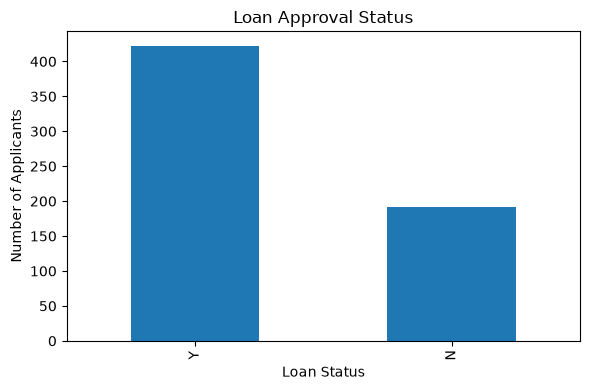

In [19]:
#LOAN APPROVAL STATUS 
plt.figure(figsize=(6, 4))

df["Loan_Status"].value_counts().plot(kind="bar")

plt.title("Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

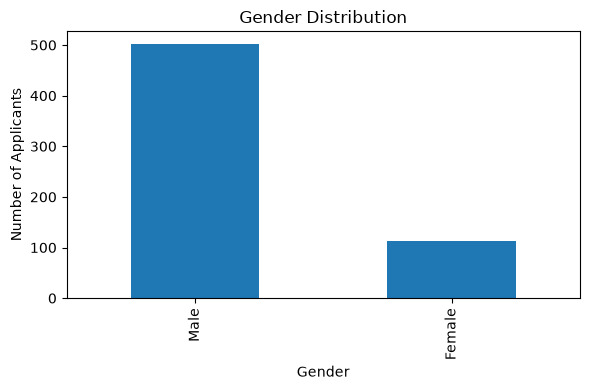

In [20]:
#GENDER DISTRIBUTION
plt.figure(figsize=(6, 4))

df["Gender"].value_counts().plot(kind="bar")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

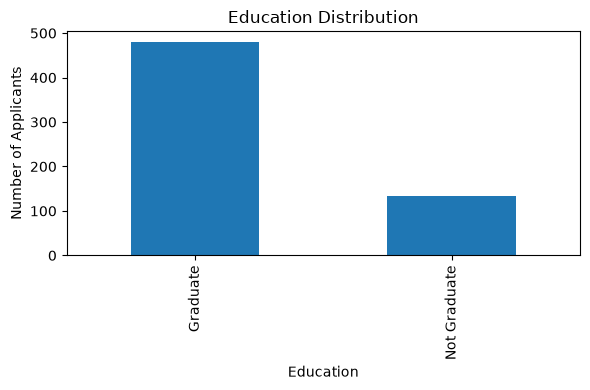

In [21]:
#EDUCATION DISTRIBUTION
plt.figure(figsize=(6, 4))

df["Education"].value_counts().plot(kind="bar")

plt.title("Education Distribution")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

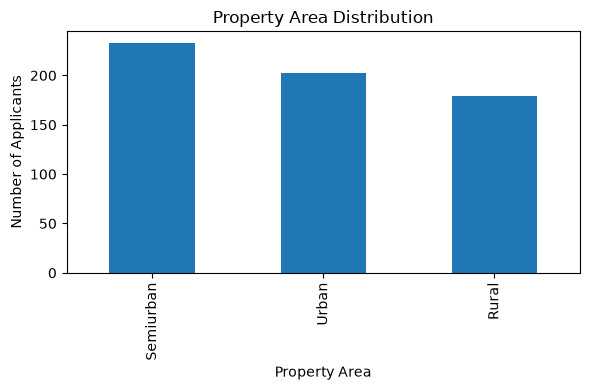

In [22]:
#PROPERTY AREA DISTRIBUTION
plt.figure(figsize=(6, 4))

df["Property_Area"].value_counts().plot(kind="bar")

plt.title("Property Area Distribution")
plt.xlabel("Property Area")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

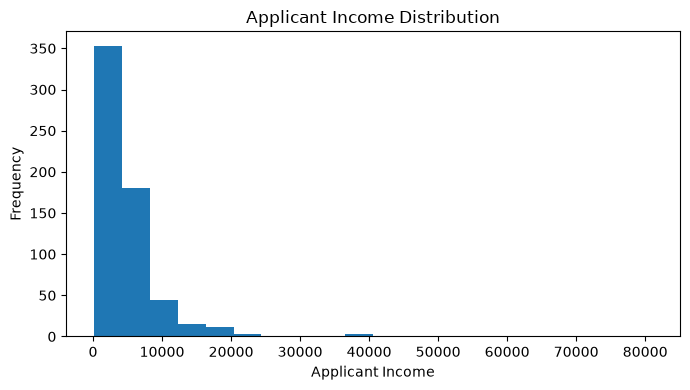

In [23]:
#Applicant Income Distribution
plt.figure(figsize=(7, 4))

plt.hist(df["ApplicantIncome"], bins=20)

plt.title("Applicant Income Distribution")
plt.xlabel("Applicant Income")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

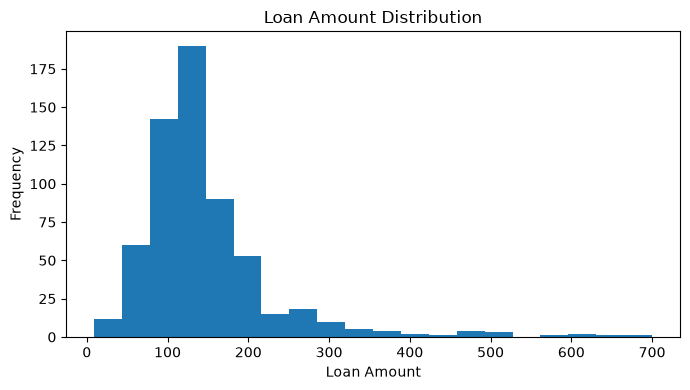

In [24]:
#Loan Amount Distribution
plt.figure(figsize=(7, 4))

plt.hist(df["LoanAmount"], bins=20)

plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

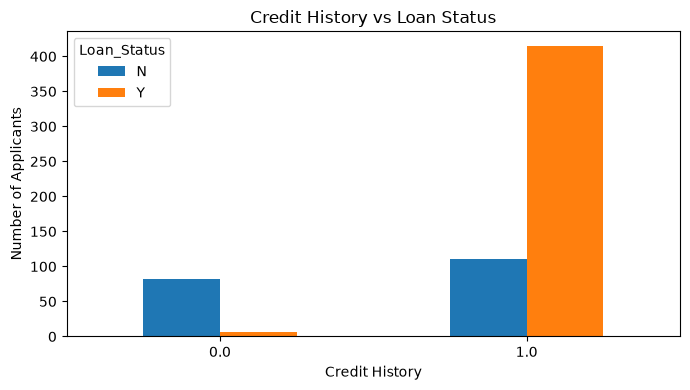

In [25]:
#Credit history vs Loan status 
credit_status = pd.crosstab(
    df["Credit_History"],
    df["Loan_Status"]
)
credit_status.plot(kind="bar", figsize=(7, 4))
plt.title("Credit History vs Loan Status")
plt.xlabel("Credit History")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

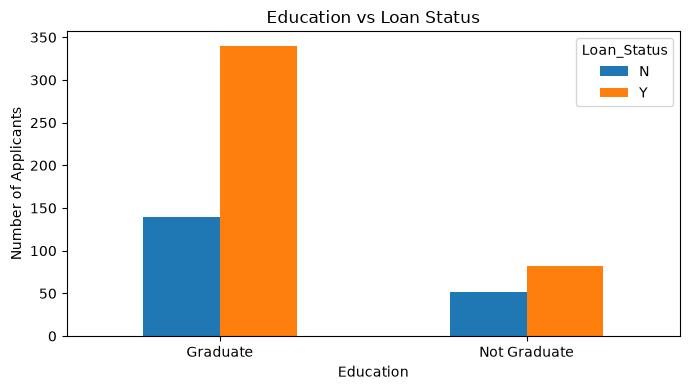

In [26]:
#Education vs Loan Status 
education_status = pd.crosstab(
    df["Education"],
    df["Loan_Status"]
)

education_status.plot(kind="bar", figsize=(7, 4))

plt.title("Education vs Loan Status")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

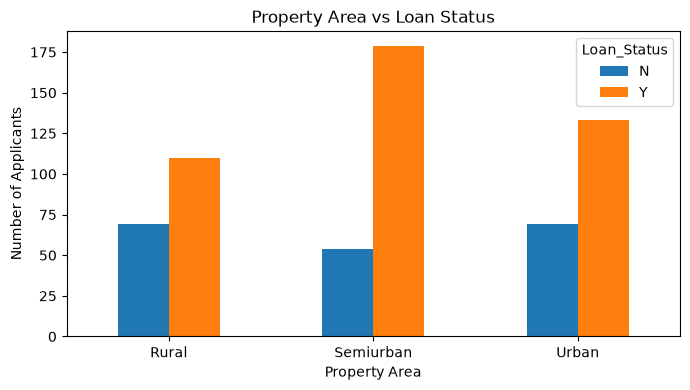

In [27]:
#property area vs loan status
property_status = pd.crosstab(
    df["Property_Area"],
    df["Loan_Status"]
)

property_status.plot(kind="bar", figsize=(7, 4))

plt.title("Property Area vs Loan Status")
plt.xlabel("Property Area")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
#DATA PREPROCESSING

In [28]:
model_df = df.copy()
print("Model dataset created successfully.")

Model dataset created successfully.


In [29]:
#lABEL ENCODING

In [30]:
le = LabelEncoder()
model_df["Gender"] = le.fit_transform(model_df["Gender"])
model_df["Married"] = le.fit_transform(model_df["Married"])
model_df["Education"] = le.fit_transform(model_df["Education"])
model_df["Self_Employed"] = le.fit_transform(model_df["Self_Employed"])

# ConvertING Loan Status into numerical form
model_df["Loan_Status"] = le.fit_transform(model_df["Loan_Status"])

print("Label Encoding completed.")
display(model_df.head())

Label Encoding completed.


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,Urban,1
1,LP001003,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,Rural,0
2,LP001005,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,Urban,1
3,LP001006,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,Urban,1
4,LP001008,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,Urban,1


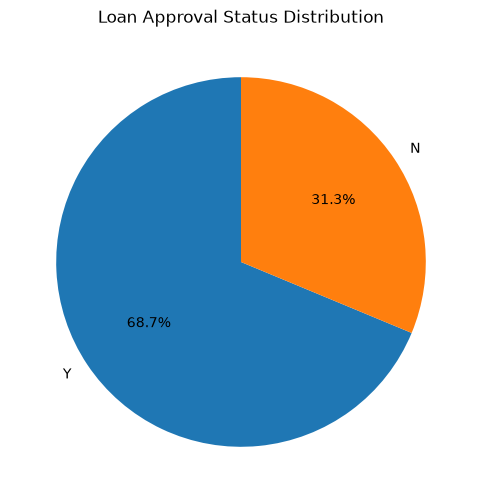

In [31]:
# Pie Chart - Loan Approval Status

loan_status_counts = df["Loan_Status"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    loan_status_counts.values,
    labels=loan_status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Loan Approval Status Distribution")

plt.show()

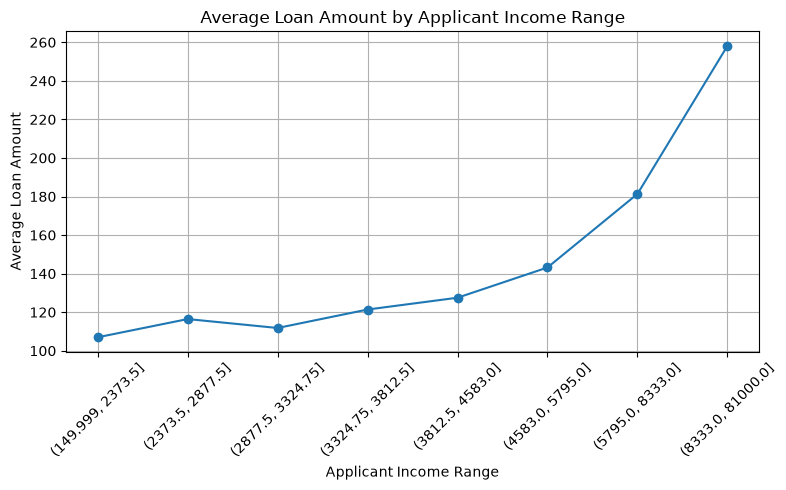

In [32]:
# Line Chart - Average Loan Amount by Applicant Income Range

line_df = df.dropna(subset=["ApplicantIncome", "LoanAmount"]).copy()

line_df["IncomeRange"] = pd.qcut(
    line_df["ApplicantIncome"],
    q=8,
    duplicates="drop"
)

line_data = line_df.groupby(
    "IncomeRange",
    observed=True
)["LoanAmount"].mean()

plt.figure(figsize=(8,5))

plt.plot(
    range(len(line_data)),
    line_data.values,
    marker="o"
)

plt.xlabel("Applicant Income Range")
plt.ylabel("Average Loan Amount")
plt.title("Average Loan Amount by Applicant Income Range")

plt.xticks(
    range(len(line_data)),
    [str(x) for x in line_data.index],
    rotation=45
)

plt.grid(True)
plt.tight_layout()
plt.show()

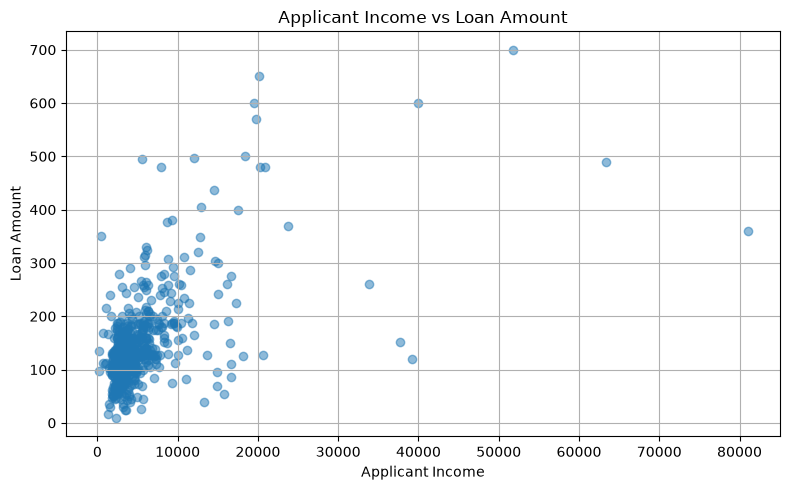

In [33]:
# Scatter Plot - Applicant Income vs Loan Amount

scatter_df = df.dropna(
    subset=["ApplicantIncome", "LoanAmount"]
)

plt.figure(figsize=(8,5))

plt.scatter(
    scatter_df["ApplicantIncome"],
    scatter_df["LoanAmount"],
    alpha=0.5
)

plt.xlabel("Applicant Income")
plt.ylabel("Loan Amount")
plt.title("Applicant Income vs Loan Amount")

plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\surya\AppData\Local\Temp\ipykernel_12148\525556002.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


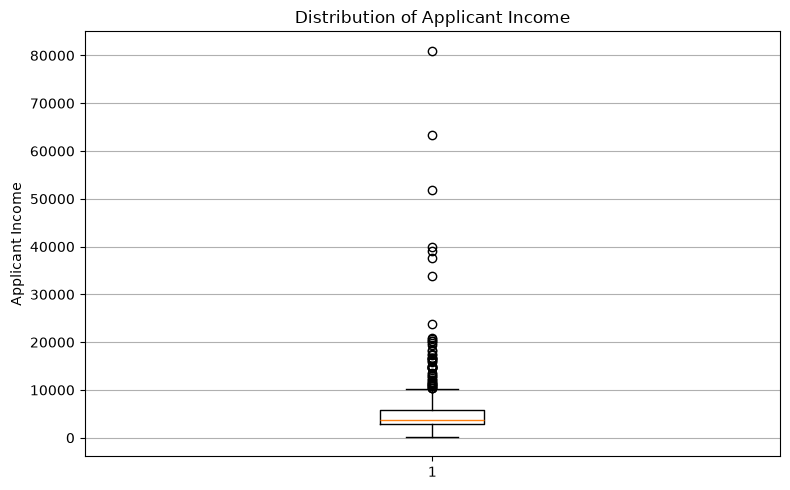

In [34]:
# Box Plot - Applicant Income

box_df = df.dropna(subset=["ApplicantIncome"])

plt.figure(figsize=(8,5))

plt.boxplot(
    box_df["ApplicantIncome"],
    vert=True
)

plt.ylabel("Applicant Income")
plt.title("Distribution of Applicant Income")

plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

In [35]:
model_df["Dependents"] = model_df["Dependents"].replace("3+", 3)

model_df["Dependents"] = model_df["Dependents"].fillna(0)

model_df["Dependents"] = model_df["Dependents"].astype(int)

print("Dependents converted successfully.")

Dependents converted successfully.


In [36]:
# 10. ONE-HOT ENCODING

In [37]:
model_df = pd.get_dummies(
    model_df,
    columns=["Property_Area"],
    drop_first=True
)

print("One-Hot Encoding completed.")
print("Columns after One-Hot Encoding:")
print(model_df.columns.tolist())

One-Hot Encoding completed.
Columns after One-Hot Encoding:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Loan_Status', 'Property_Area_Semiurban', 'Property_Area_Urban']


In [38]:
# Converting Boolean columns into integer values
for column in model_df.columns:
    if model_df[column].dtype == "bool":
        model_df[column] = model_df[column].astype(int)

print("Boolean values converted to integers.")

Boolean values converted to integers.


In [39]:
# Remove Loan_ID
model_df = model_df.drop("Loan_ID", axis=1)

print("Loan_ID removed.")
display(model_df.head())

Loan_ID removed.


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,1,0,1
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0,0
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,1,0,1
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,1,0,1
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,1,0,1


In [40]:
#11.FEATURE SCALING

In [41]:
features_to_scale = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]
scaler = MinMaxScaler()
model_df[features_to_scale] = scaler.fit_transform(
    model_df[features_to_scale]
)

print("Feature Scaling using Min-Max Scaling completed.")
display(model_df[features_to_scale].head())

Feature Scaling using Min-Max Scaling completed.


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,0.070489,0.000000,0.172214,0.74359
1,0.054830,0.036192,0.172214,0.74359
2,0.035250,0.000000,0.082489,0.74359
3,0.030093,0.056592,0.160637,0.74359
4,0.072356,0.000000,0.191027,0.74359


In [42]:
#12. STANDARDIZATION

In [ ]:
standard_scaler = StandardScaler()
standardized_data = standard_scaler.fit_transform(
    df[
        [
            "ApplicantIncome",
            "CoapplicantIncome",
            "LoanAmount",
            "Loan_Amount_Term"
        ]
    ]
)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=[
        "ApplicantIncome",
        "CoapplicantIncome",
        "LoanAmount",
        "Loan_Amount_Term"
    ]
)

print("Standardization completed.")


Standardization completed.


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,0.072991,-0.554487,-0.211241,0.273231
1,-0.134412,-0.038732,-0.211241,0.273231
2,-0.393747,-0.554487,-0.948996,0.273231
3,-0.462062,0.251980,-0.306435,0.273231
4,0.097728,-0.554487,-0.056551,0.273231


In [ ]:
display(standardized_df.head())

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,0.072991,-0.554487,-0.211241,0.273231
1,-0.134412,-0.038732,-0.211241,0.273231
2,-0.393747,-0.554487,-0.948996,0.273231
3,-0.462062,0.251980,-0.306435,0.273231
4,0.097728,-0.554487,-0.056551,0.273231


In [44]:
#13.CORRELATION ANALYSIS

In [45]:
correlation = model_df.corr()

print("Correlation Matrix:")
display(correlation)

Correlation Matrix:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban
Gender,1.000000,0.364569,0.172914,0.045364,-0.000525,0.058809,0.082912,0.106904,-0.074030,0.009170,0.017987,-0.108623,0.034530
Married,0.364569,1.000000,0.334216,0.012304,0.004489,0.051708,0.075948,0.146546,-0.100912,0.010938,0.091478,0.005845,0.000546
Dependents,0.172914,0.334216,1.000000,0.055752,0.056798,0.118202,0.030430,0.163103,-0.103864,-0.040160,0.010118,0.001924,-0.001198
Education,0.045364,0.012304,0.055752,1.000000,-0.010383,-0.140760,-0.062290,-0.168759,-0.073928,-0.073658,-0.085884,-0.039410,-0.034279
Self_Employed,-0.000525,0.004489,0.056798,-0.010383,1.000000,0.127180,-0.016100,0.115100,-0.033739,-0.001550,-0.003700,0.008710,-0.030338
ApplicantIncome,0.058809,0.051708,0.118202,-0.140760,0.127180,1.000000,-0.116605,0.565181,-0.046531,-0.018615,-0.004710,-0.014246,-0.000598
CoapplicantIncome,0.082912,0.075948,0.030430,-0.062290,-0.016100,-0.116605,1.000000,0.189218,-0.059383,0.011134,-0.059187,-0.027044,0.022776
LoanAmount,0.106904,0.146546,0.163103,-0.168759,0.115100,0.565181,0.189218,1.000000,0.036960,-0.000607,-0.033214,-0.005804,-0.036050
Loan_Amount_Term,-0.074030,-0.100912,-0.103864,-0.073928,-0.033739,-0.046531,-0.059383,0.036960,1.000000,-0.004705,-0.022549,0.059141,-0.094279
Credit_History,0.009170,0.010938,-0.040160,-0.073658,-0.001550,-0.018615,0.011134,-0.000607,-0.004705,1.000000,0.540556,0.035976,-0.016934


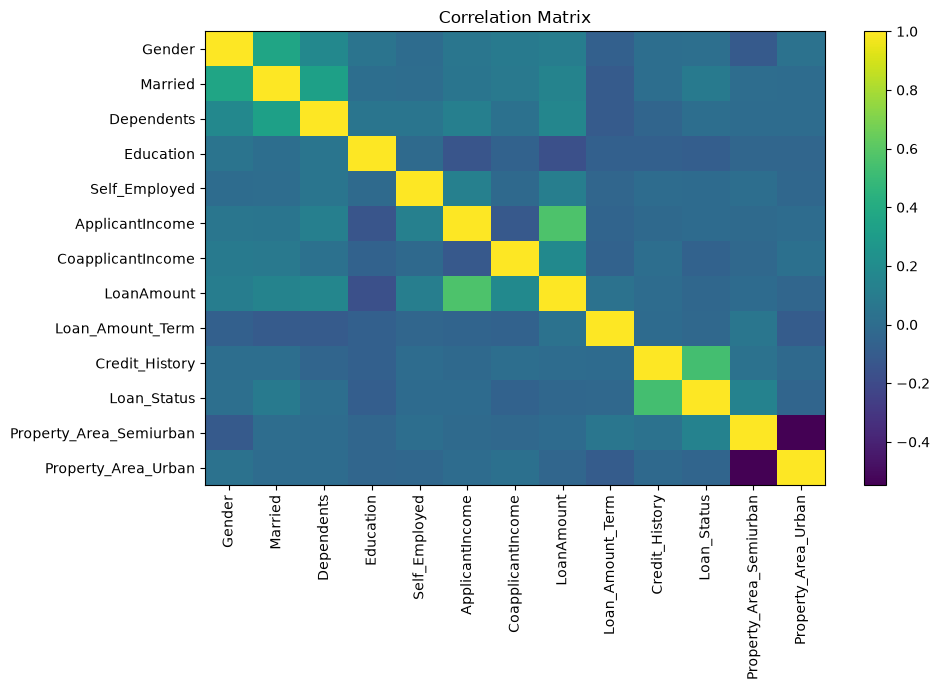

In [46]:
#Correlation Visualization
plt.figure(figsize=(10, 7))

plt.imshow(correlation, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [47]:
#14.FEATURE SELECTION

In [48]:
print("Available Model Features:")
print(model_df.columns.tolist())

Available Model Features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Loan_Status', 'Property_Area_Semiurban', 'Property_Area_Urban']


In [49]:
features = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History",
    "Property_Area_Semiurban",
    "Property_Area_Urban"
]

X = model_df[features]

y = model_df["Loan_Status"]

print("Selected Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print("Loan_Status")

Selected Features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area_Semiurban', 'Property_Area_Urban']

Target Variable:
Loan_Status


In [50]:
#15. TRAIN-TEST SPLIT

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# print("Training data shape:", X_train.shape)
# print("Testing data shape:", X_test.shape)

print("X_Train:",X_train.shape)
print("X_Test:",X_test.shape)
print("Y_Train:",y_train.shape)
print("Y_Test:", y_train.shape)


X_Train: (491, 12)
X_Test: (123, 12)
Y_Train: (491,)
Y_Test: (491,)


In [48]:
# 16. LOGISTIC REGRESSION MODEL

In [53]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [56]:
#17. MAKING PREDICTIONS

In [54]:
y_pred = model.predict(X_test)

print("Predictions generated successfully.")
print(y_pred[:10])

Predictions generated successfully.
[0 1 1 1 1 1 1 1 1 1]


In [58]:
#18. MODEL EVALUATION

In [55]:
#accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", round(accuracy * 100, 2), "%")

Model Accuracy: 0.8536585365853658
Model Accuracy (%): 85.37 %


In [56]:
#classification report 
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.55      0.70        38
           1       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



In [53]:
#19. CONFUSION MATRIX

In [54]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[21 17]
 [ 1 84]]


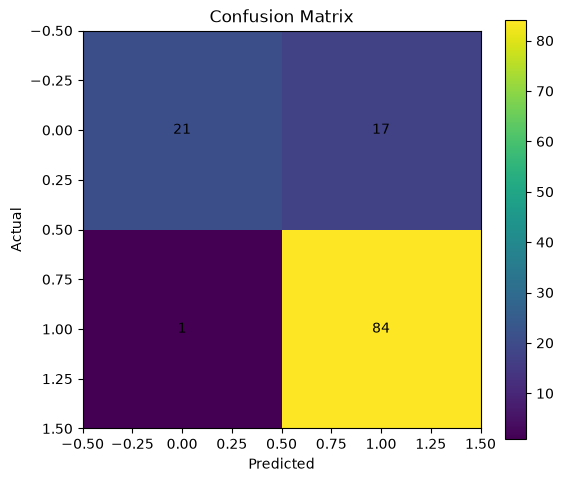

In [55]:
#Confusion matrix visualization
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

for i in range(len(cm)):
    for j in range(len(cm[i])):
        plt.text(
            j,
            i,
            cm[i][j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [56]:
# 20. LOGISTIC REGRESSION COEFFICIENTS
feature_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

feature_coefficients = feature_coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

print("Logistic Regression Feature Coefficients:")
display(feature_coefficients)

Logistic Regression Feature Coefficients:


,Feature,Coefficient
9,Credit_History,3.124445
10,Property_Area_Semiurban,0.693950
1,Married,0.481488
11,Property_Area_Urban,0.103203
2,Dependents,0.086184
8,Loan_Amount_Term,0.046775
5,ApplicantIncome,0.037252
0,Gender,-0.156768
4,Self_Employed,-0.191613
7,LoanAmount,-0.276750


In [61]:
#21.FINAL LOAN PREDICTION

In [57]:
print("Loan Status Encoding:")
print(le.classes_)

Loan Status Encoding:
['N' 'Y']


In [58]:
#sample
sample = X_test.iloc[0:1]

prediction = model.predict(sample)

if prediction[0] == 1:
    print("Prediction: Loan Approved")
else:
    print("Prediction: Loan Not Approved")

Prediction: Loan Not Approved
